<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week5_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Jupyter Notebook – Support Vector Machines
## Predicting Loan Default with SVM

### Project Overview

For Week 5, I am continuing to use the Credit Risk dataset from my capstone project. I am keeping `loan_status` as the target variable so I can compare the results with the logistic regression model from Week 4.

This week, I am using Support Vector Machines (SVM) to predict whether a borrower defaults. I will start with a linear SVM and then use different kernels to see if a nonlinear decision boundary improves the model.

I will also test different regularization values to see how the value of C affects model performance.

The main question I am looking at is:

**Can Support Vector Machines improve the prediction of loan default, and how do different kernels and regularization values affect model performance?**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

pd.set_option('display.max_columns', None)

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)

df.head()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
File loaded: credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = (
    continuous_features +
    categorical_features +
    [target]
)

data = df[model_columns].copy()

print(
    "Rows before removing missing values:",
    len(data)
)

data = data.dropna()

print(
    "Rows after removing missing values:",
    len(data)
)

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_status
0,22,59000,123.0,35000,16.02,0.59,3,RENT,PERSONAL,D,Y,1
1,21,9600,5.0,1000,11.14,0.10,2,OWN,EDUCATION,B,N,0
2,25,9600,1.0,5500,12.87,0.57,3,MORTGAGE,MEDICAL,C,N,1
3,23,65500,4.0,35000,15.23,0.53,2,RENT,MEDICAL,C,N,1
4,24,54400,8.0,35000,14.27,0.55,4,RENT,MEDICAL,C,Y,1


## Predictor Variables

I am using the same target and predictors that I used for logistic regression in Week 4. This will make it easier to compare logistic regression and SVM without changing the underlying data.

The target is `loan_status`, and the predictors include borrower income, age, employment length, loan amount, interest rate, loan percent income, credit history length, home ownership, loan intent, loan grade, and previous default history.

I am continuing to include `loan_percent_income` because the target is loan default rather than loan amount, so the target leakage issue from the earlier linear regression analysis does not apply here.

In [ ]:
X = data[
    continuous_features +
    categorical_features
]

y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

print("\nTraining class distribution:")

print(
    y_train
    .value_counts(normalize=True)
    .round(4)
)

print("\nTesting class distribution:")

print(
    y_test
    .value_counts(normalize=True)
    .round(4)
)

Training observations: 22910
Testing observations: 5728

Training class distribution:
loan_status
0    0.7834
1    0.2166
Name: proportion, dtype: float64

Testing class distribution:
loan_status
0    0.7833
1    0.2167
Name: proportion, dtype: float64


## Feature Scaling

Feature scaling is especially important for SVM because the model uses distances between observations when finding the decision boundary.

Some of the continuous variables in this dataset are measured on very different scales. For example, borrower income is much larger numerically than variables such as interest rate or loan percent income.

I standardized the continuous variables before fitting the SVM models so that variables with larger numerical values do not have an unfair influence on the model.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            StandardScaler(),
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

## Linear Support Vector Machine

I started with a linear SVM as my baseline SVM model. A linear SVM tries to find a decision boundary that separates the two classes while creating as much space as possible between the boundary and the closest observations.

I started with C = 1, which gives me a baseline before testing different regularization values later in the notebook.

In [ ]:
linear_svm = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'svm',
            SVC(
                kernel='linear',
                C=1,
                probability=True,
                random_state=42
            )
        )
    ]
)

linear_svm.fit(
    X_train,
    y_train
)

linear_pred = linear_svm.predict(
    X_test
)

linear_prob = linear_svm.predict_proba(
    X_test
)[:, 1]

In [ ]:
linear_accuracy = accuracy_score(
    y_test,
    linear_pred
)

linear_precision = precision_score(
    y_test,
    linear_pred
)

linear_recall = recall_score(
    y_test,
    linear_pred
)

linear_f1 = f1_score(
    y_test,
    linear_pred
)

linear_auc = roc_auc_score(
    y_test,
    linear_prob
)

print("Linear SVM")
print("-" * 40)

print(f"Accuracy:  {linear_accuracy:.4f}")
print(f"Precision: {linear_precision:.4f}")
print(f"Recall:    {linear_recall:.4f}")
print(f"F1 Score:  {linear_f1:.4f}")
print(f"ROC-AUC:   {linear_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        linear_pred
    )
)

Linear SVM
----------------------------------------
Accuracy:  0.8610
Precision: 0.7615
Recall:    0.5222
F1 Score:  0.6195
ROC-AUC:   0.8569

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      4487
           1       0.76      0.52      0.62      1241

    accuracy                           0.86      5728
   macro avg       0.82      0.74      0.77      5728
weighted avg       0.85      0.86      0.85      5728



## The Kernel Trick

A linear SVM assumes that the classes can be separated using a linear decision boundary. However, the relationship between borrower characteristics and default may be more complicated than that.

The kernel trick allows an SVM to model nonlinear relationships without directly creating a large number of new features.

I tested two additional kernels:

- RBF (Radial Basis Function)
- Polynomial

I will compare these models with the linear SVM to see whether allowing a nonlinear decision boundary improves default prediction.

In [ ]:
rbf_svm = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'svm',
            SVC(
                kernel='rbf',
                C=1,
                gamma='scale',
                probability=True,
                random_state=42
            )
        )
    ]
)

rbf_svm.fit(
    X_train,
    y_train
)

rbf_pred = rbf_svm.predict(
    X_test
)

rbf_prob = rbf_svm.predict_proba(
    X_test
)[:, 1]

In [ ]:
rbf_accuracy = accuracy_score(
    y_test,
    rbf_pred
)

rbf_precision = precision_score(
    y_test,
    rbf_pred
)

rbf_recall = recall_score(
    y_test,
    rbf_pred
)

rbf_f1 = f1_score(
    y_test,
    rbf_pred
)

rbf_auc = roc_auc_score(
    y_test,
    rbf_prob
)

print("RBF SVM")
print("-" * 40)

print(f"Accuracy:  {rbf_accuracy:.4f}")
print(f"Precision: {rbf_precision:.4f}")
print(f"Recall:    {rbf_recall:.4f}")
print(f"F1 Score:  {rbf_f1:.4f}")
print(f"ROC-AUC:   {rbf_auc:.4f}")

RBF SVM
----------------------------------------
Accuracy:  0.9099
Precision: 0.9426
Recall:    0.6221
F1 Score:  0.7495
ROC-AUC:   0.8927


In [ ]:
poly_svm = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'svm',
            SVC(
                kernel='poly',
                degree=3,
                C=1,
                gamma='scale',
                probability=True,
                random_state=42
            )
        )
    ]
)

poly_svm.fit(
    X_train,
    y_train
)

poly_pred = poly_svm.predict(
    X_test
)

poly_prob = poly_svm.predict_proba(
    X_test
)[:, 1]

In [ ]:
poly_accuracy = accuracy_score(
    y_test,
    poly_pred
)

poly_precision = precision_score(
    y_test,
    poly_pred
)

poly_recall = recall_score(
    y_test,
    poly_pred
)

poly_f1 = f1_score(
    y_test,
    poly_pred
)

poly_auc = roc_auc_score(
    y_test,
    poly_prob
)

print("Polynomial SVM")
print("-" * 40)

print(f"Accuracy:  {poly_accuracy:.4f}")
print(f"Precision: {poly_precision:.4f}")
print(f"Recall:    {poly_recall:.4f}")
print(f"F1 Score:  {poly_f1:.4f}")
print(f"ROC-AUC:   {poly_auc:.4f}")

Polynomial SVM
----------------------------------------
Accuracy:  0.9064
Precision: 0.9232
Recall:    0.6197
F1 Score:  0.7416
ROC-AUC:   0.8825


## Kernel Comparison

I compared the linear, RBF, and polynomial kernels using the same training and testing data.

If the nonlinear kernels perform better than the linear SVM, that would suggest that the relationship between the predictors and loan default is not completely linear.

I am comparing accuracy, precision, recall, F1 score, and ROC-AUC because each metric gives a different view of classification performance.

In [ ]:
kernel_results = pd.DataFrame({
    'Model': [
        'Linear SVM',
        'RBF SVM',
        'Polynomial SVM'
    ],

    'Accuracy': [
        linear_accuracy,
        rbf_accuracy,
        poly_accuracy
    ],

    'Precision': [
        linear_precision,
        rbf_precision,
        poly_precision
    ],

    'Recall': [
        linear_recall,
        rbf_recall,
        poly_recall
    ],

    'F1 Score': [
        linear_f1,
        rbf_f1,
        poly_f1
    ],

    'ROC-AUC': [
        linear_auc,
        rbf_auc,
        poly_auc
    ]
})

kernel_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Linear SVM,0.8610,0.7615,0.5222,0.6195,0.8569
1,RBF SVM,0.9099,0.9426,0.6221,0.7495,0.8927
2,Polynomial SVM,0.9064,0.9232,0.6197,0.7416,0.8825


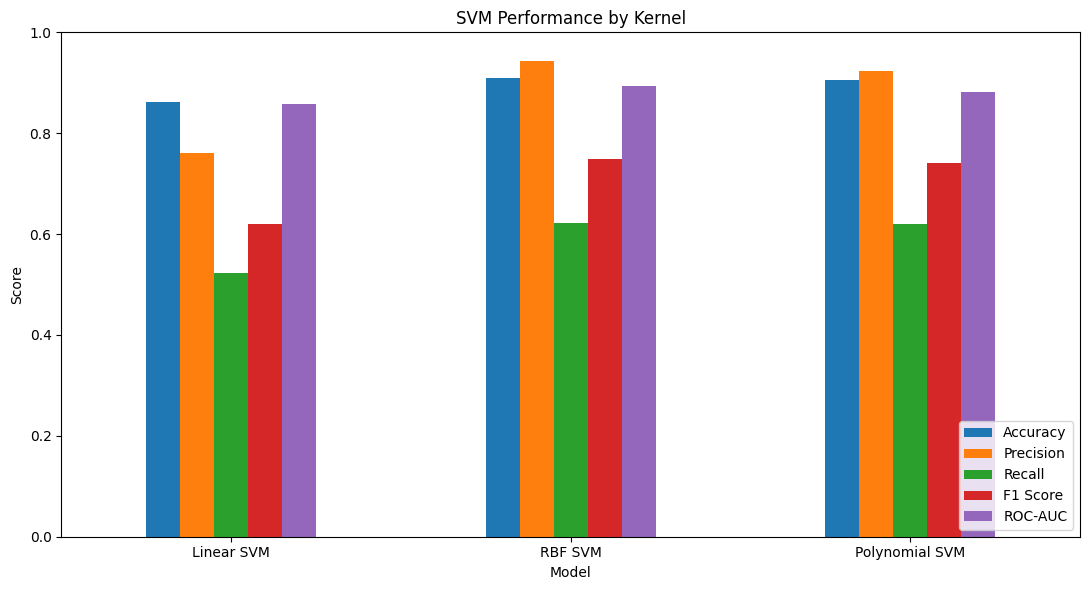

In [ ]:
plot_results = kernel_results.set_index(
    'Model'
)

plot_results.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.ylabel('Score')

plt.title(
    'SVM Performance by Kernel'
)

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    loc='lower right'
)

plt.tight_layout()
plt.show()

## SVM Regularization

The C parameter controls regularization in an SVM.

A smaller C allows more classification errors in exchange for a wider margin and stronger regularization. A larger C places a larger penalty on classification errors and tries to fit the training data more closely.

I tested several C values using the RBF kernel to see how the amount of regularization affects performance.

In [ ]:
c_values = [
    0.01,
    0.1,
    1,
    10
]

regularization_results = []

for c in c_values:

    model = Pipeline(
        steps=[
            (
                'preprocessor',
                preprocessor
            ),
            (
                'svm',
                SVC(
                    kernel='rbf',
                    C=c,
                    gamma='scale',
                    probability=False,
                    random_state=42
                )
            )
        ]
    )

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(
        X_train
    )

    test_pred = model.predict(
        X_test
    )

    regularization_results.append({
        'C': c,

        'Train Accuracy':
            accuracy_score(
                y_train,
                train_pred
            ),

        'Test Accuracy':
            accuracy_score(
                y_test,
                test_pred
            ),

        'Precision':
            precision_score(
                y_test,
                test_pred,
                zero_division=0
            ),

        'Recall':
            recall_score(
                y_test,
                test_pred,
                zero_division=0
            ),

        'F1 Score':
            f1_score(
                y_test,
                test_pred,
                zero_division=0
            )
    })

regularization_df = pd.DataFrame(
    regularization_results
)

regularization_df.round(4)

,C,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,0.01,0.8507,0.8451,0.8899,0.3255,0.4767
1,0.10,0.8975,0.8884,0.8992,0.5463,0.6797
2,1.00,0.9216,0.9099,0.9426,0.6221,0.7495
3,10.00,0.9339,0.9148,0.9333,0.6535,0.7687


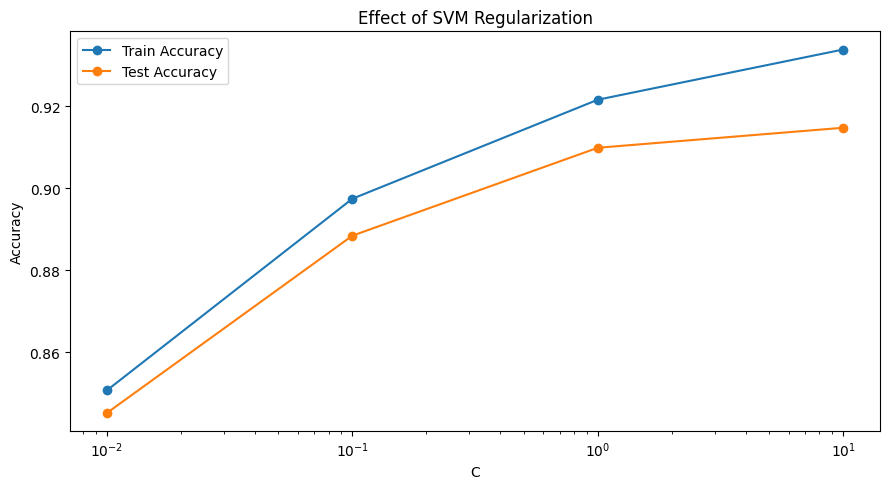

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    regularization_df['C'],
    regularization_df['Train Accuracy'],
    marker='o',
    label='Train Accuracy'
)

plt.plot(
    regularization_df['C'],
    regularization_df['Test Accuracy'],
    marker='o',
    label='Test Accuracy'
)

plt.xscale('log')

plt.xlabel('C')
plt.ylabel('Accuracy')

plt.title(
    'Effect of SVM Regularization'
)

plt.legend()

plt.tight_layout()
plt.show()

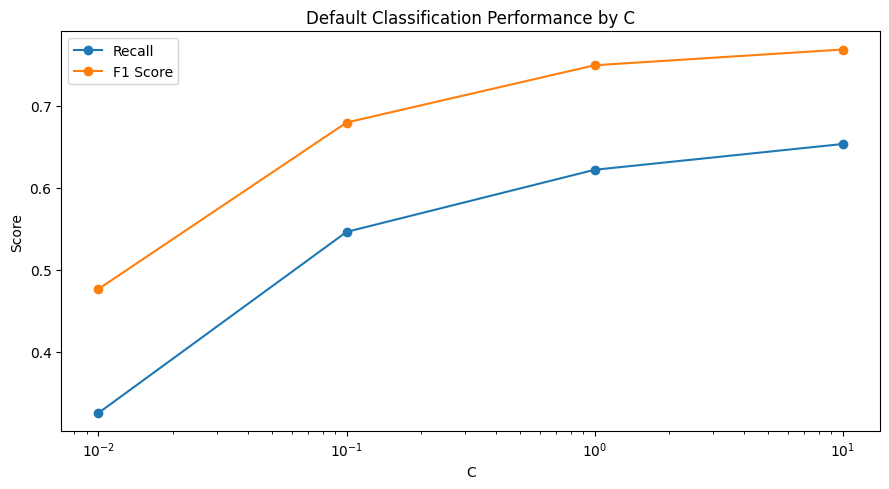

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    regularization_df['C'],
    regularization_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    regularization_df['C'],
    regularization_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xscale('log')

plt.xlabel('C')
plt.ylabel('Score')

plt.title(
    'Default Classification Performance by C'
)

plt.legend()

plt.tight_layout()
plt.show()

## Effect of Regularization

I compared training and testing accuracy across several values of C to see whether changing the amount of regularization affected the model.

I also looked at recall and F1 score because accuracy alone may hide poor performance on the smaller default class.

A very large difference between training and testing performance could indicate overfitting. On the other hand, a very small C may regularize the model too much and cause it to underfit.

In [ ]:
best_c = regularization_df.loc[
    regularization_df['F1 Score'].idxmax(),
    'C'
]

print(
    "Best C based on F1 Score:",
    best_c
)

Best C based on F1 Score: 10.0


In [ ]:
tuned_rbf = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'svm',
            SVC(
                kernel='rbf',
                C=best_c,
                gamma='scale',
                probability=True,
                random_state=42
            )
        )
    ]
)

tuned_rbf.fit(
    X_train,
    y_train
)

tuned_pred = tuned_rbf.predict(
    X_test
)

tuned_prob = tuned_rbf.predict_proba(
    X_test
)[:, 1]

In [ ]:
tuned_accuracy = accuracy_score(
    y_test,
    tuned_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_pred
)

tuned_recall = recall_score(
    y_test,
    tuned_pred
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred
)

tuned_auc = roc_auc_score(
    y_test,
    tuned_prob
)

print("Tuned RBF SVM")
print("-" * 40)

print(f"Best C:     {best_c}")
print(f"Accuracy:   {tuned_accuracy:.4f}")
print(f"Precision:  {tuned_precision:.4f}")
print(f"Recall:     {tuned_recall:.4f}")
print(f"F1 Score:   {tuned_f1:.4f}")
print(f"ROC-AUC:    {tuned_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        tuned_pred
    )
)

Tuned RBF SVM
----------------------------------------
Best C:     10.0
Accuracy:   0.9148
Precision:  0.9333
Recall:     0.6535
F1 Score:   0.7687
ROC-AUC:    0.8994

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      4487
           1       0.93      0.65      0.77      1241

    accuracy                           0.91      5728
   macro avg       0.92      0.82      0.86      5728
weighted avg       0.92      0.91      0.91      5728



## Confusion Matrix

I used a confusion matrix to look more closely at the predictions from the tuned RBF SVM.

As in Week 4, I am especially interested in false negatives. These represent borrowers who actually defaulted but were predicted as non-defaults.

Looking at the confusion matrix helps show whether the SVM is actually identifying defaulting borrowers instead of producing a high overall accuracy mainly by predicting the larger non-default class.

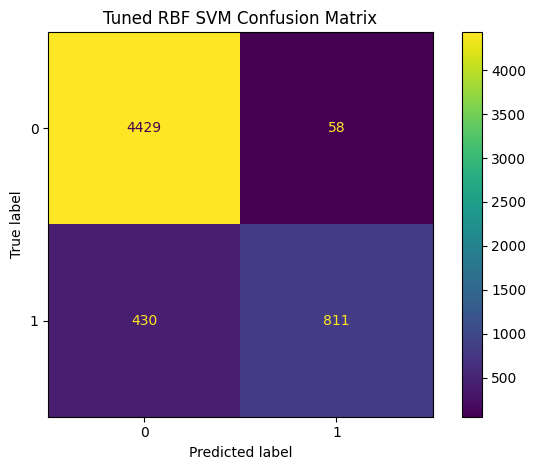

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred
)

plt.title(
    'Tuned RBF SVM Confusion Matrix'
)

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

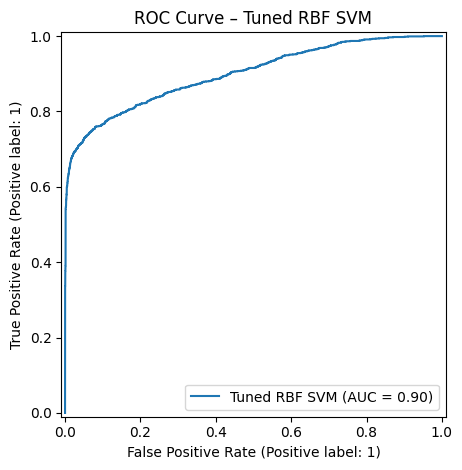

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    tuned_prob,
    name='Tuned RBF SVM'
)

plt.title(
    'ROC Curve – Tuned RBF SVM'
)

plt.tight_layout()
plt.show()

## Comparison with Week 4 Logistic Regression

Since I am using the same target and predictors as Week 4, I can also compare the tuned SVM with my scaled logistic regression model.

This comparison will help me see whether allowing a nonlinear decision boundary improves default prediction compared with logistic regression.

I am especially interested in recall and F1 score because identifying actual defaults is an important part of this credit risk problem.

In [ ]:
week4_vs_week5 = pd.DataFrame({
    'Model': [
        'Week 4 Scaled Logistic Regression',
        'Week 5 Tuned RBF SVM'
    ],

    'Accuracy': [
        0.8600,
        tuned_accuracy
    ],

    'Precision': [
        0.7532,
        tuned_precision
    ],

    'Recall': [
        0.5262,
        tuned_recall
    ],

    'F1 Score': [
        0.6195,
        tuned_f1
    ],

    'ROC-AUC': [
        0.8617,
        tuned_auc
    ]
})

week4_vs_week5.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Week 4 Scaled Logistic Regression,0.8600,0.7532,0.5262,0.6195,0.8617
1,Week 5 Tuned RBF SVM,0.9148,0.9333,0.6535,0.7687,0.8994


In [ ]:
best_kernel = kernel_results.loc[
    kernel_results['F1 Score'].idxmax(),
    'Model'
]

best_kernel_auc = kernel_results.loc[
    kernel_results['ROC-AUC'].idxmax(),
    'Model'
]

tuned_cm = confusion_matrix(
    y_test,
    tuned_pred
)

tn, fp, fn, tp = tuned_cm.ravel()

print("WEEK 5 MODEL SUMMARY")
print("=" * 60)

print(
    "Best baseline kernel by F1:",
    best_kernel
)

print(
    "Best baseline kernel by ROC-AUC:",
    best_kernel_auc
)

print(
    "Best RBF C by F1:",
    best_c
)

print("\nTuned RBF SVM")
print("-" * 60)

print(
    f"Accuracy: {tuned_accuracy:.4f}"
)

print(
    f"Precision: {tuned_precision:.4f}"
)

print(
    f"Recall: {tuned_recall:.4f}"
)

print(
    f"F1 Score: {tuned_f1:.4f}"
)

print(
    f"ROC-AUC: {tuned_auc:.4f}"
)

print("\nConfusion Matrix")
print("-" * 60)

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

WEEK 5 MODEL SUMMARY
Best baseline kernel by F1: RBF SVM
Best baseline kernel by ROC-AUC: RBF SVM
Best RBF C by F1: 10.0

Tuned RBF SVM
------------------------------------------------------------
Accuracy: 0.9148
Precision: 0.9333
Recall: 0.6535
F1 Score: 0.7687
ROC-AUC: 0.8994

Confusion Matrix
------------------------------------------------------------
True Negatives: 4429
False Positives: 58
False Negatives: 430
True Positives: 811


## Week 5 Conclusions

For Week 5, I used Support Vector Machines to predict loan default and compared linear, RBF, and polynomial kernels. I also tested different values of C to see how regularization affected the RBF model.

### Kernel Comparison

The linear SVM had an accuracy of 0.8610, recall of 0.5222, F1 score of 0.6195, and ROC-AUC of 0.8569. These results were very similar to the scaled logistic regression model from Week 4.

Both nonlinear kernels performed better than the linear SVM. The polynomial SVM increased accuracy to 0.9064 and had an F1 score of 0.7416. The RBF SVM performed slightly better, with an accuracy of 0.9099, precision of 0.9426, recall of 0.6221, F1 score of 0.7495, and ROC-AUC of 0.8927.

The improvement from the nonlinear kernels suggests that the relationship between the borrower characteristics and loan default is not completely linear. The RBF kernel was the strongest of the three kernels based on both F1 score and ROC-AUC.

### Regularization

I tested C values of 0.01, 0.1, 1, and 10 using the RBF kernel. Performance generally improved as C increased.

At C = 0.01, recall was only 0.3255 and the F1 score was 0.4767. At C = 1, recall increased to 0.6221 and the F1 score increased to 0.7495. The best results occurred at C = 10, which produced a recall of 0.6535 and an F1 score of 0.7687.

The training and testing accuracy at C = 10 were 0.9339 and 0.9148. There was a slightly larger difference between training and testing performance as C increased, but the test results also continued to improve. Based on the values I tested, C = 10 provided the strongest overall performance.

### Tuned RBF SVM

The final tuned RBF SVM had an accuracy of 0.9148, precision of 0.9333, recall of 0.6535, F1 score of 0.7687, and ROC-AUC of 0.8994.

The confusion matrix showed that the model correctly identified 4,429 non-defaults and 811 defaults. There were only 58 false positives, but the model still missed 430 borrowers who actually defaulted.

Although the model still missed some defaults, it correctly identified about 65% of the defaulting borrowers while maintaining very high precision. This was a noticeable improvement over the models I tested previously.

### Comparison with Week 4

The tuned RBF SVM performed better than the scaled logistic regression model from Week 4 across every metric. Accuracy increased from 0.8600 to 0.9148, while ROC-AUC increased from 0.8617 to 0.8994.

The biggest improvements were in precision, recall, and F1 score. Precision increased from 0.7532 to 0.9333, recall increased from 0.5262 to 0.6535, and the F1 score increased from 0.6195 to 0.7687.

This means the SVM was not only more accurate overall, but it was also better at identifying borrowers who actually defaulted.

### Overall Conclusion

Overall, the RBF SVM was the strongest model I tested this week. The nonlinear kernels performed noticeably better than the linear SVM, which suggests that loan default has nonlinear relationships with the borrower and loan characteristics in this dataset.

Regularization also had an important effect on performance. Increasing C allowed the RBF model to fit the data more closely, and C = 10 produced the best results out of the values I tested.

Compared with Week 4, the SVM provided a clear improvement over logistic regression. This is one of the stronger results from my analysis so far because it shows that changing the type of model, rather than only changing preprocessing or feature selection, can improve the ability to identify borrowers who are at risk of default.